# Image Caption Generator (VGG16 + LSTM) with Voice Output

In [3]:
import os, re, pickle, random
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from nltk.translate.bleu_score import corpus_bleu

from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, add

WORKING_DIR = '/kaggle/working'
os.makedirs(WORKING_DIR, exist_ok=True)

## 1. Dataset

In [2]:
# Download Flickr8k
%pip install -q kagglehub
import kagglehub

BASE_DIR = kagglehub.dataset_download("adityajn105/flickr8k")
directory = os.path.join(BASE_DIR, 'Images')
print("Dataset path:", BASE_DIR)

Using Colab cache for faster access to the 'flickr8k' dataset.
Dataset path: /kaggle/input/flickr8k


## 2. Image features (VGG16)
Extracted once in batches and cached to `features.pkl`; later runs just load the cache.

In [4]:
FEATURES_PATH = os.path.join(WORKING_DIR, 'features.pkl')
BATCH = 64

if os.path.exists(FEATURES_PATH):
    with open(FEATURES_PATH, 'rb') as f:
        features = pickle.load(f)
else:
    # VGG16 without the final classifier -> 4096-d fc2 features
    vgg = VGG16()
    vgg = Model(inputs=vgg.inputs, outputs=vgg.layers[-2].output)
    vgg.summary()

    img_names = os.listdir(directory)
    features = {}
    for start in tqdm(range(0, len(img_names), BATCH)):
        names = img_names[start:start + BATCH]
        images = np.stack([img_to_array(load_img(os.path.join(directory, n), target_size=(224, 224)))
                           for n in names])
        feats = vgg.predict(preprocess_input(images), verbose=0)
        for name, feat in zip(names, feats):
            features[os.path.splitext(name)[0]] = feat[None]  # shape (1, 4096), same as before

    with open(FEATURES_PATH, 'wb') as f:
        pickle.dump(features, f)

print(len(features), "images")

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,260,544 (512.16 MB)

 Trainable params: 134,260,544 (512.16 MB)

 Non-trainable params: 0 (0.00 B)

  0%|          | 0/127 [00:00<?, ?it/s]

8091 images


## 3. Captions

In [16]:
# image id -> list of its captions
mapping = defaultdict(list)
with open(os.path.join(BASE_DIR, 'captions.txt'), encoding='utf-8') as f:
    next(f)  # skip header
    for line in f:
        if len(line.strip()) < 2:
            continue
        image_id, *caption = line.strip().split(',')
        mapping[image_id.split('.')[0]].append(" ".join(caption))


def clean_text(caption):
    # lowercase, keep letters only, drop one-letter words, add start/end tags
    caption = re.sub(r'[^a-z\s]', '', caption.lower())
    words = [w for w in caption.split() if len(w) > 1]
    return 'startseq ' + ' '.join(words) + ' endseq'


for key, captions in mapping.items():
    mapping[key] = [clean_text(c) for c in captions]

all_captions = [c for captions in mapping.values() for c in captions]

In [6]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(all_captions)
vocab_size = len(tokenizer.word_index) + 1
max_length = max(len(c.split()) for c in all_captions)

# encode every caption once (instead of re-tokenising every epoch)
sequences = {key: tokenizer.texts_to_sequences(caps) for key, caps in mapping.items()}

# shuffled 90/10 split, fixed seed so results are reproducible
image_ids = list(mapping.keys())
random.Random(42).shuffle(image_ids)
split = int(len(image_ids) * 0.90)
train, test = image_ids[:split], image_ids[split:]

print("vocab_size:", vocab_size, "| max_length:", max_length, "| train/test:", len(train), len(test))

vocab_size: 8768 | max_length: 34 | train/test: 7281 810


## 4. Model

In [7]:
# yields batches of `batch_size` images (all their caption prefixes) to keep memory low
def data_generator(data_keys, sequences, features, max_length, vocab_size, batch_size):
    X1, X2, y = [], [], []
    n = 0
    while True:
        for key in data_keys:
            n += 1
            for seq in sequences[key]:
                for i in range(1, len(seq)):
                    X1.append(features[key][0])
                    X2.append(seq[:i])
                    y.append(seq[i])
            if n == batch_size:
                yield ({"image": np.array(X1),
                        "text": pad_sequences(X2, maxlen=max_length, padding='post')},
                       to_categorical(y, num_classes=vocab_size))
                X1, X2, y = [], [], []
                n = 0

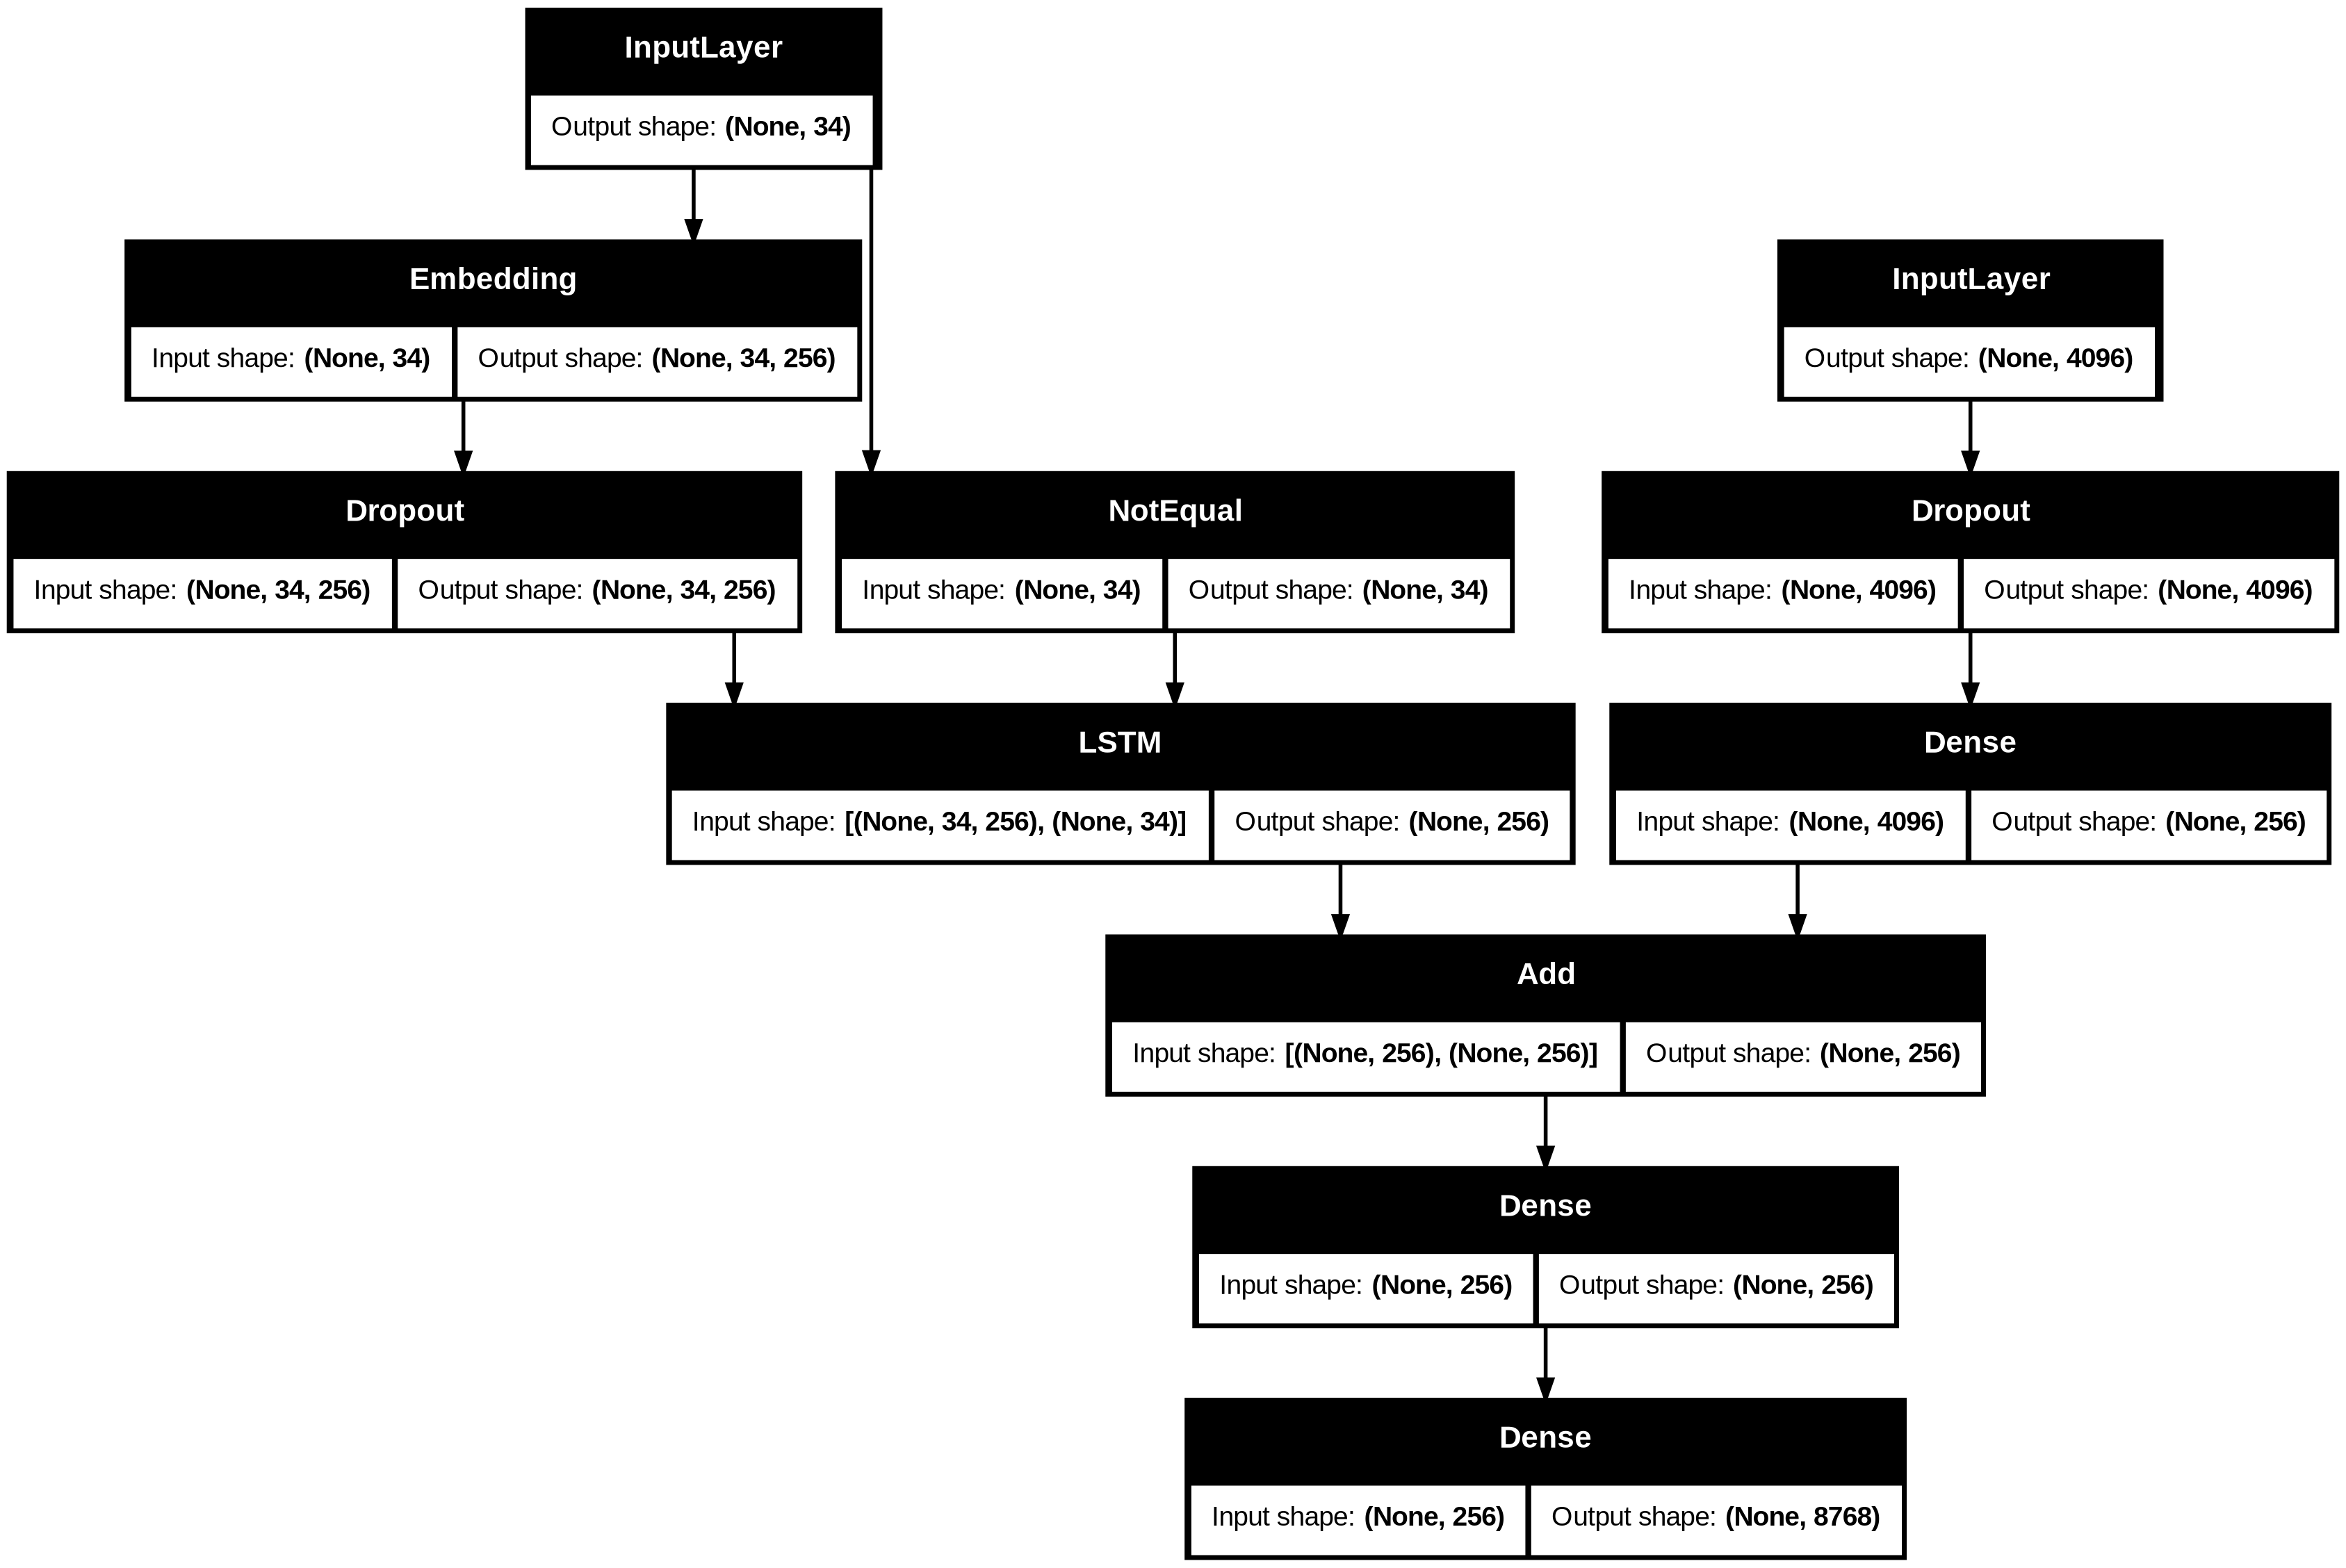

In [8]:
# encoder: image features
inputs1 = Input(shape=(4096,), name="image")
fe1 = Dropout(0.4)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

# encoder: text sequence
inputs2 = Input(shape=(max_length,), name="text")
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.4)(se1)
se3 = LSTM(256)(se2)

# decoder
decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)
model.compile(loss='categorical_crossentropy', optimizer='adam')
plot_model(model, show_shapes=True)

In [9]:
epochs = 20
batch_size = 32
steps = len(train) // batch_size

for i in range(epochs):
    # fresh generator each epoch so every epoch starts from the first image
    generator = data_generator(train, sequences, features, max_length, vocab_size, batch_size)
    model.fit(generator, epochs=1, steps_per_epoch=steps, verbose=1)

model.save(os.path.join(WORKING_DIR, 'best_model.keras'))

227/227 ━━━━━━━━━━━━━━━━━━━━ 47s 158ms/step - loss: 5.1423
227/227 ━━━━━━━━━━━━━━━━━━━━ 35s 156ms/step - loss: 3.9217
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 150ms/step - loss: 3.5003
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 149ms/step - loss: 3.2347
227/227 ━━━━━━━━━━━━━━━━━━━━ 35s 153ms/step - loss: 3.0402
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 150ms/step - loss: 2.8990
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 151ms/step - loss: 2.7920
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 149ms/step - loss: 2.7052
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 150ms/step - loss: 2.6273
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - loss: 2.5605
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 149ms/step - loss: 2.5000
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - loss: 2.4459
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - loss: 2.3966
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - loss: 2.3519
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 147ms/step - loss: 2.3099
227/227 ━━━━━━━━━━━━━━━━━━━━ 34s 148ms/step - loss: 2.2741
227/227 ━━━━━━━━━━━━━━━━━━━━ 33s 147ms/step - loss: 2.24

## 5. Evaluation

In [10]:
def predict_caption(model, image, tokenizer, max_length):
    # greedy decoding: repeatedly predict the next word until 'endseq'
    in_text = 'startseq'
    for _ in range(max_length):
        sequence = pad_sequences(tokenizer.texts_to_sequences([in_text]), maxlen=max_length, padding='post')
        yhat = model.predict({"image": image, "text": sequence}, verbose=0)
        word = tokenizer.index_word.get(int(np.argmax(yhat)))
        if word is None:
            break
        in_text += ' ' + word
        if word == 'endseq':
            break
    return in_text


def strip_tags(words):
    return [w for w in words if w not in ('startseq', 'endseq')]

In [11]:
# BLEU without the startseq/endseq tags (they always match and inflate the score)
actual, predicted = [], []
for key in tqdm(test):
    actual.append([strip_tags(c.split()) for c in mapping[key]])
    predicted.append(strip_tags(predict_caption(model, features[key], tokenizer, max_length).split()))

print("BLEU-1: %f" % corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0)))
print("BLEU-2: %f" % corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0)))

  0%|          | 0/810 [00:00<?, ?it/s]

BLEU-1: 0.443108
BLEU-2: 0.259214


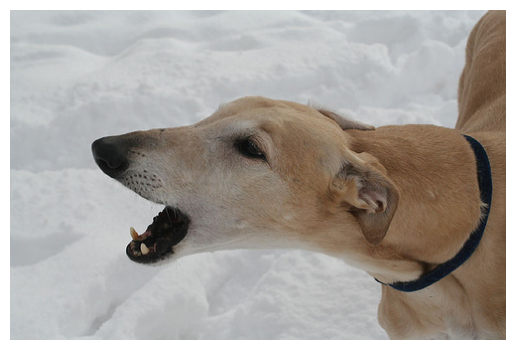

Actual captions:
  startseq brown dog barks surrounded by white snow endseq
  startseq dog wearing black collar is standing open mouthed in the snow endseq
  startseq tan dog with black collar barking in the snow endseq
  startseq dog barking endseq
  startseq dog standing in snow barking endseq
Predicted caption: startseq brown dog is carrying something in its mouth endseq


In [12]:
def show_image(image_id):
    plt.imshow(Image.open(os.path.join(directory, image_id + '.jpg')))
    plt.axis('off')
    plt.show()


# random test image: actual vs predicted
image_id = random.choice(test)
show_image(image_id)
print('Actual captions:')
for caption in mapping[image_id]:
    print(' ', caption)
print('Predicted caption:', predict_caption(model, features[image_id], tokenizer, max_length))

## 6. Voice Assistant (Gemini API)
Reads the caption generated by our model out loud, for blind / visually impaired users.

Pipeline: **image → VGG16 + LSTM caption → Gemini (polish text) → Gemini TTS (speech) → audio**

Get a free API key at https://aistudio.google.com/apikey and set it as `GEMINI_API_KEY`
(environment variable, or a Kaggle/Colab secret). Never hard-code the key in the notebook.

In [13]:
%pip install -q google-genai

In [20]:
import wave
from google import genai
from google.genai import types
from IPython.display import Audio, display

# get the API key from Colab secrets (key icon in the left sidebar), never write it in the code
from google.colab import userdata
api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)
TEXT_MODEL = "gemini-3.8-flash"
TTS_MODEL = "gemini-3.8-flash-tts"
VOICE = "Kore"

In [21]:
def improve_caption(caption):
    prompt = (
        "Rewrite this image caption as one clear, natural sentence for a voice assistant "
        "describing a photo to a blind person. Fix the grammar only and do not add any "
        "details that are not in the caption. Return only the sentence.\n\n"
        f"Caption: {caption}"
    )
    try:
        response = client.models.generate_content(model=TEXT_MODEL, contents=prompt)
        return response.text.strip()
    except Exception as e:
        print("Gemini couldn't rewrite the caption, using the original one:", e)
        return caption


def text_to_speech(text, file_name="caption.wav"):
    response = client.models.generate_content(
        model=TTS_MODEL,
        contents=text,
        config=types.GenerateContentConfig(
            response_modalities=["AUDIO"],
            speech_config=types.SpeechConfig(
                voice_config=types.VoiceConfig(
                    prebuilt_voice_config=types.PrebuiltVoiceConfig(voice_name=VOICE)
                )
            ),
        ),
    )
    audio_data = response.candidates[0].content.parts[0].inline_data.data

    # Gemini returns raw audio (16-bit, 24000 Hz, mono), so I save it as a wav file
    with wave.open(file_name, "wb") as wf:
        wf.setnchannels(1)
        wf.setsampwidth(2)
        wf.setframerate(24000)
        wf.writeframes(audio_data)
    return file_name

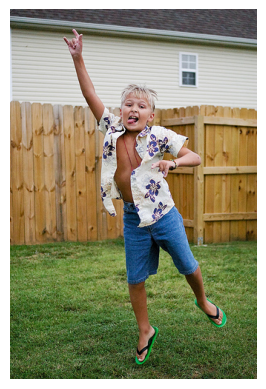

Gemini couldn't rewrite the caption, using the original one: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Model caption  : girl in white shirt is jumping on the grass
Spoken sentence: girl in white shirt is jumping on the grass


In [26]:
def describe_and_speak(image_id=None):
    if image_id is None:
        image_id = random.choice(test)
    show_image(image_id)

    caption = predict_caption(model, features[image_id], tokenizer, max_length)
    caption = caption.replace('startseq', '').replace('endseq', '').strip()
    sentence = improve_caption(caption)

    print("Model caption  :", caption)
    print("Spoken sentence:", sentence)

    try:
        audio_file = text_to_speech(sentence)
        display(Audio(audio_file))
    except Exception as e:
        print("Text to speech failed:", e)


# picks a random test image, run it again to try another one
describe_and_speak()

**Notes**
- `polish=False` speaks the raw model caption (uses only the TTS call).
- If TTS is unavailable or rate-limited, the error is printed and the caption text is still shown.
- The audio is saved as `caption.wav`, so it can also be used in an app or on the wearable device.

In [27]:
# save what the deployed app needs besides the model: the word dictionary and the max caption length
with open(os.path.join(WORKING_DIR, 'tokenizer.pkl'), 'wb') as f:
    pickle.dump({'word_index': tokenizer.word_index, 'max_length': max_length}, f)

import tensorflow as tf
print("TensorFlow version:", tf.__version__)

# download the two files the app needs to your computer
from google.colab import files
files.download(os.path.join(WORKING_DIR, 'best_model.keras'))
files.download(os.path.join(WORKING_DIR, 'tokenizer.pkl'))

TensorFlow version: 2.21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>